In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np

df = pd.read_csv('evaluated_result.csv')

# coerce LLM score columns to numeric (turns 'skipped (generation error)' → NaN)
for col in ['llm_accuracy', 'llm_coherence', 'llm_language']:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# flag error rows
df['is_error'] = df['generated_abstract'].astype(str).str.startswith('ERROR:')

# ── group num_of_neighbors into bins of 5 (1-5, 6-10, 11-15, …) ──────────────
BIN_SIZE = 5
max_neighbors = int(df['num_of_neighbors'].max())
bin_edges = list(range(0, max_neighbors + BIN_SIZE, BIN_SIZE))
NEIGHBOR_GROUPS = [f'{lo + 1}-{lo + BIN_SIZE}' for lo in bin_edges[:-1]]
df['neighbor_group'] = pd.cut(
    df['num_of_neighbors'], bins=bin_edges, labels=NEIGHBOR_GROUPS, right=True
)

def weighted_group_mean(frame: pd.DataFrame, value_col: str) -> pd.Series:
    """Mean of value_col per neighbour_group, weighted by num_of_neighbors."""
    def _wavg(g):
        mask = g[value_col].notna()
        if not mask.any():
            return np.nan
        return np.average(g.loc[mask, value_col], weights=g.loc[mask, 'num_of_neighbors'])
    return frame.groupby('neighbor_group', observed=True)[[value_col, 'num_of_neighbors']].apply(_wavg).reindex(NEIGHBOR_GROUPS)

print(f'{len(df)} rows  |  {df["is_error"].sum()} generation errors')
df.head(3)


945 rows  |  0 generation errors


,node_id,mag_id,original_abstract,generated_abstract,rouge1_f,rouge2_f,rougeL_f,bertscore_p,bertscore_r,bertscore_f1,llm_accuracy,llm_coherence,llm_language,num_of_neighbors,is_error,neighbor_group
0,1089,2953793718,"We deal with the \textit{selective classification} problem (supervised-learning problem with a rejection option), where we want to achieve the best performance at a certain level of coverage of the data. We transform the original $m$-class classification problem to $(m+1)$-class where the $(m+1)$-th class represents the model abstaining from making a prediction due to uncertainty. Inspired by portfolio theory, we propose a loss function for the selective classification problem based on the doubling rate of gambling. We show that minimizing this loss function has a natural interpretation as maximizing the return of a \textit{horse race}, where a player aims to balance between betting on an outcome (making a prediction) when confident and reserving one's winnings (abstaining) when not confident. This loss function allows us to train neural networks and characterize the uncertainty of prediction in an end-to-end fashion. In comparison with previous methods, our method requires almost no modification to the model inference algorithm or neural architecture. Experimentally, we show that our method can identify both uncertain and outlier data points, and achieves strong results on SVHN and CIFAR10 at various coverages of the data.","We propose a novel approach to the problem of learning a deep neural network for the task of image classification. Our approach is based on the idea of using a deep neural network as a feature extractor, and then training a linear classifier on top of the features extracted from the training images. We show that this approach can be used to train a deep neural network with a large number of layers, and that it can be used to train a deep neural network with a large number of parameters. We also show that this approach can be used to train a deep neural network with a large number of training images.",0.3442,0.0850,0.2013,0.8606,0.8109,0.8350,2,7,7,69,False,66-70
1,1102,2958885478,"Traditional 3D Convolutional Neural Networks (CNNs) are computationally expensive, memory intensive, prone to overfit, and most importantly, there is a need to improve their feature learning capabilities. To address these issues, we propose Rectified Local Phase Volume (ReLPV) block, an efficient alternative to the standard 3D convolutional layer. The ReLPV block extracts the phase in a 3D local neighborhood (e.g., 3x3x3) of each position of the input map to obtain the feature maps. The phase is extracted by computing 3D Short Term Fourier Transform (STFT) at multiple fixed low frequency points in the 3D local neighborhood of each position. These feature maps at different frequency points are then linearly combined after passing them through an activation function. The ReLPV block provides significant parameter savings of at least, 3^3 to 13^3 times compared to the standard 3D convolutional layer with the filter sizes 3x3x3 to 13x13x13, respectively. We show that the feature learning capabilities of the ReLPV block are significantly better than the standard 3D convolutional layer. Furthermore, it produces consistently better results across different 3D data representations. We achieve state-of-the-art accuracy on the volumetric ModelNet10 and ModelNet40 datasets while utilizing only 11% parameters of the current state-of-the-art. We also improve the state-of-the-art on the UCF-101 split-1 action recognition dataset by 5.68% (when trained from scratch) while using only 15% of the parameters of the state-of-the-art. The project webpage is available at this https URL.","We propose a novel approach to the problem of learning a deep neural network for image classification. Our approach is based on the observation that the training of a deep network can be viewed as a sequence of tasks, where each task is to learn a new l

In [16]:
# ── shared plot style ──────────────────────────────────────────────────────────
plt.rcParams.update({
    'figure.dpi': 120,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.35,
    'grid.linestyle': '--',
})

def bar_plot(series: pd.Series, title: str, ylabel: str,
             color: str, ylim=None, int_yaxis=False):
    """Bar chart with one bar per neighbour-count group (e.g. 1-5, 6-10, …)."""
    values = [series.get(g, np.nan) for g in NEIGHBOR_GROUPS]
    x = np.arange(len(NEIGHBOR_GROUPS))

    fig, ax = plt.subplots(figsize=(11, 4))
    bars = ax.bar(x, values, color=color, edgecolor='white', linewidth=0.6)

    # label bars that have data
    for bar, v in zip(bars, values):
        if not np.isnan(v):
            label = f'{int(v)}' if int_yaxis else f'{v:.3f}'
            ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.004 * (bar.get_height() or 1),
                    label, ha='center', va='bottom', fontsize=7)

    ax.set_xticks(x)
    ax.set_xticklabels(NEIGHBOR_GROUPS, rotation=45, ha='right')
    ax.set_xlabel('Number of neighbours', fontsize=11)
    ax.set_ylabel(ylabel, fontsize=11)
    ax.set_title(title, fontsize=13, fontweight='bold', pad=10)
    if ylim:
        ax.set_ylim(*ylim)
    if int_yaxis:
        ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
    fig.tight_layout()
    plt.show()


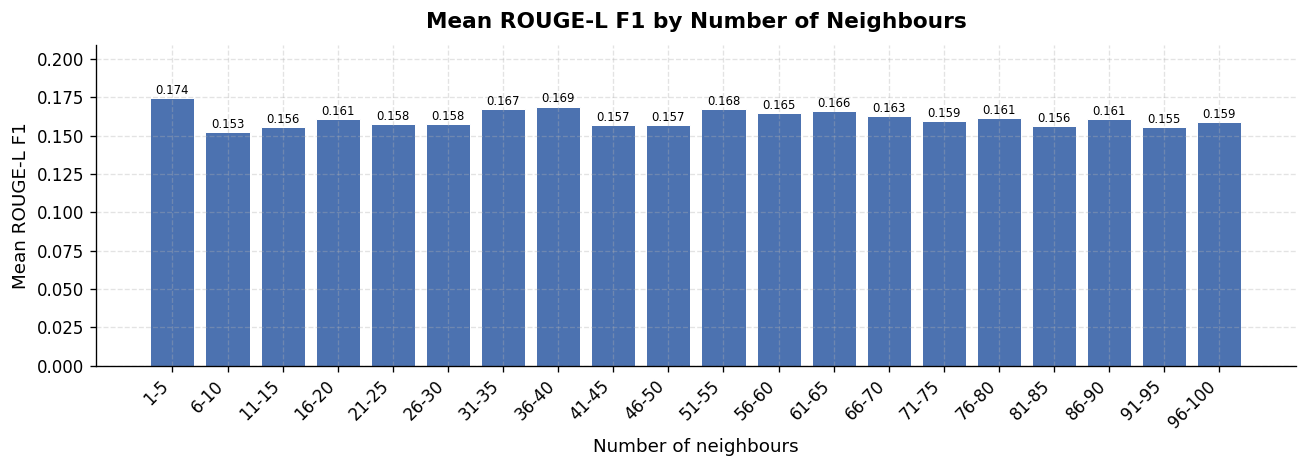

In [17]:
# ── 1. Mean ROUGE-L F1 ────────────────────────────────────────────────────────
rougel_mean = weighted_group_mean(df, 'rougeL_f')
bar_plot(rougel_mean,
         title='Mean ROUGE-L F1 by Number of Neighbours',
         ylabel='Mean ROUGE-L F1',
         color='#4C72B0',
         ylim=(0, max(rougel_mean.dropna()) * 1.2))

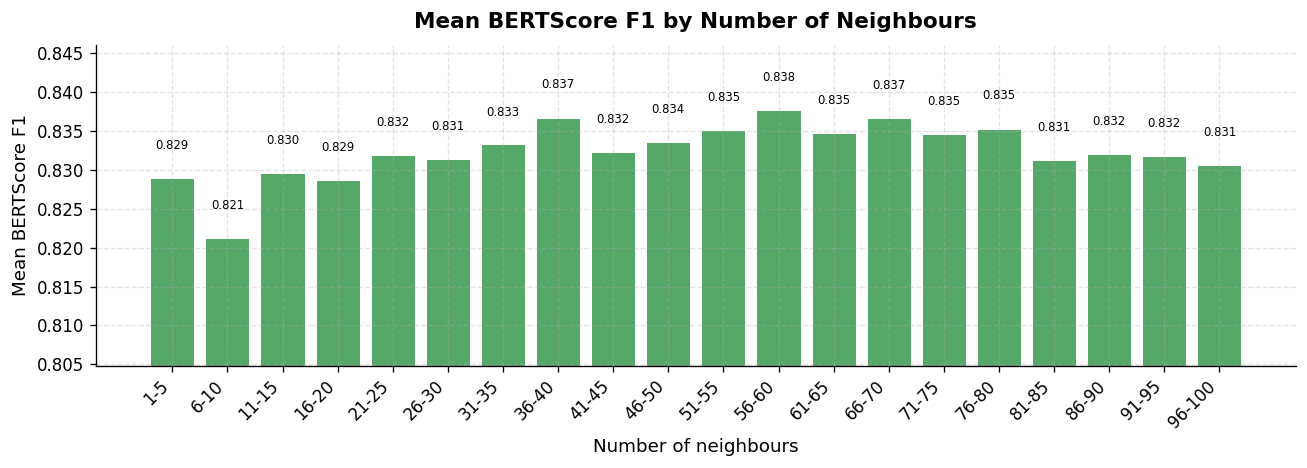

In [18]:
# ── 2. Mean BERTScore F1 ──────────────────────────────────────────────────────
bert_mean = weighted_group_mean(df, 'bertscore_f1')
ymin = bert_mean.dropna().min() * 0.98
ymax = bert_mean.dropna().max() * 1.01
bar_plot(bert_mean,
         title='Mean BERTScore F1 by Number of Neighbours',
         ylabel='Mean BERTScore F1',
         color='#55A868',
         ylim=(ymin, ymax))

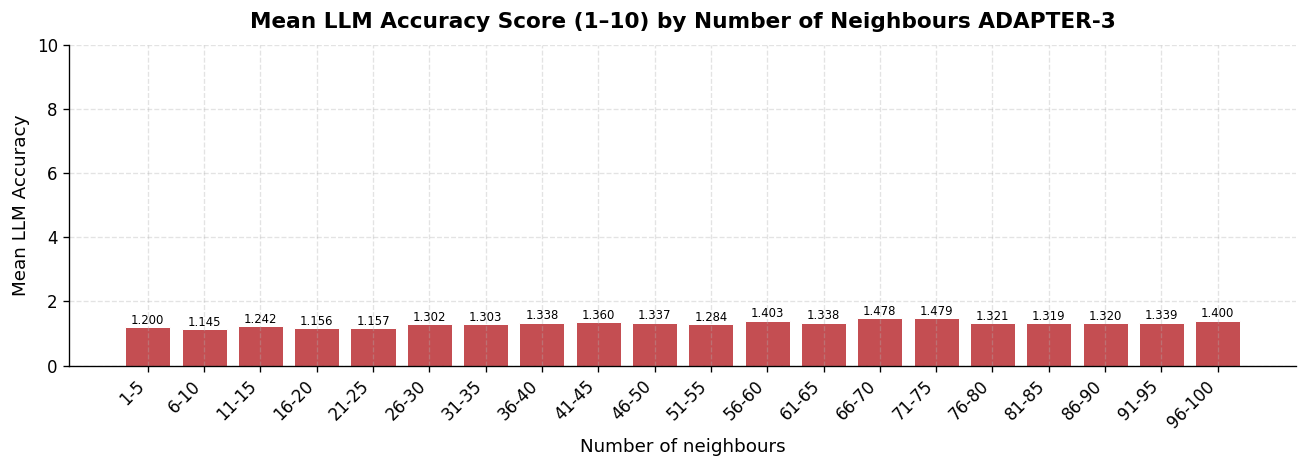

1.3142857142857143
1.0


In [19]:
# ── 3. Mean LLM Accuracy ──────────────────────────────────────────────────────
acc_mean = weighted_group_mean(df, 'llm_accuracy')
bar_plot(acc_mean,
         title='Mean LLM Accuracy Score (1–10) by Number of Neighbours ADAPTER-3',
         ylabel='Mean LLM Accuracy',
         color='#C44E52',
         ylim=(0, 10))

print(df['llm_accuracy'].mean())
print(df['llm_accuracy'].median())

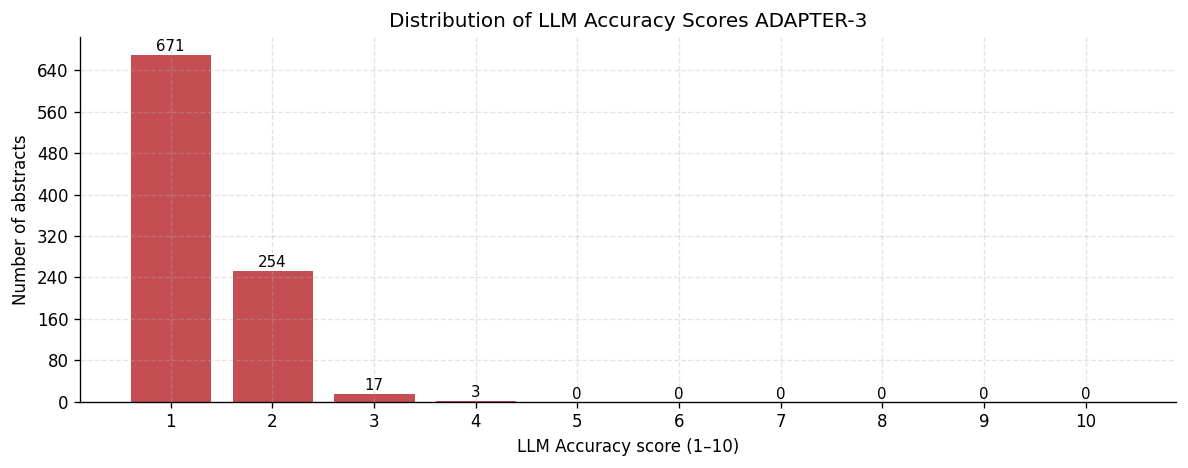

llm_accuracy
1     671
2     254
3      17
4       3
5       0
6       0
7       0
8       0
9       0
10      0
Name: count, dtype: int64

In [20]:
# ── LLM Accuracy score distribution ───────────────────────────────────────────
SCORE_RANGE = list(range(1, 11))
acc_counts = (
    df['llm_accuracy'].dropna().astype(int)
    .value_counts()
    .reindex(SCORE_RANGE, fill_value=0)
)

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(SCORE_RANGE, acc_counts.values, color='#C44E52',
              edgecolor='white', linewidth=0.6)
for bar, v in zip(bars, acc_counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
            str(int(v)), ha='center', va='bottom', fontsize=9)

ax.set_title('Distribution of LLM Accuracy Scores ADAPTER-3')
ax.set_xlabel('LLM Accuracy score (1–10)')
ax.set_ylabel('Number of abstracts')
ax.set_xticks(SCORE_RANGE)
ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
plt.tight_layout()
plt.show()

acc_counts

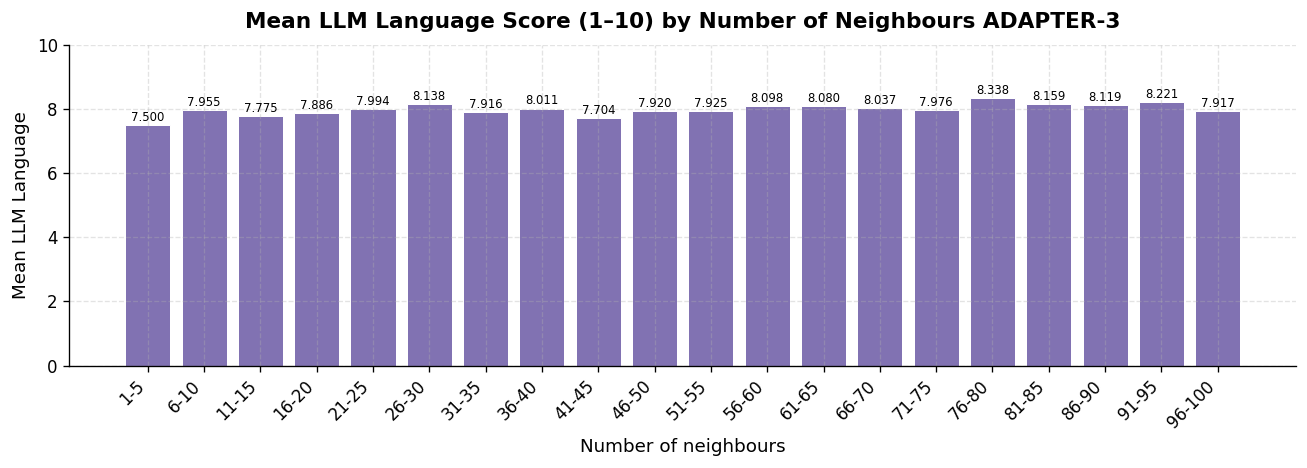

In [21]:
# ── 4. Mean LLM Language ──────────────────────────────────────────────────────
lang_mean = weighted_group_mean(df, 'llm_language')
bar_plot(lang_mean,
         title='Mean LLM Language Score (1–10) by Number of Neighbours ADAPTER-3',
         ylabel='Mean LLM Language',
         color='#8172B2',
         ylim=(0, 10))

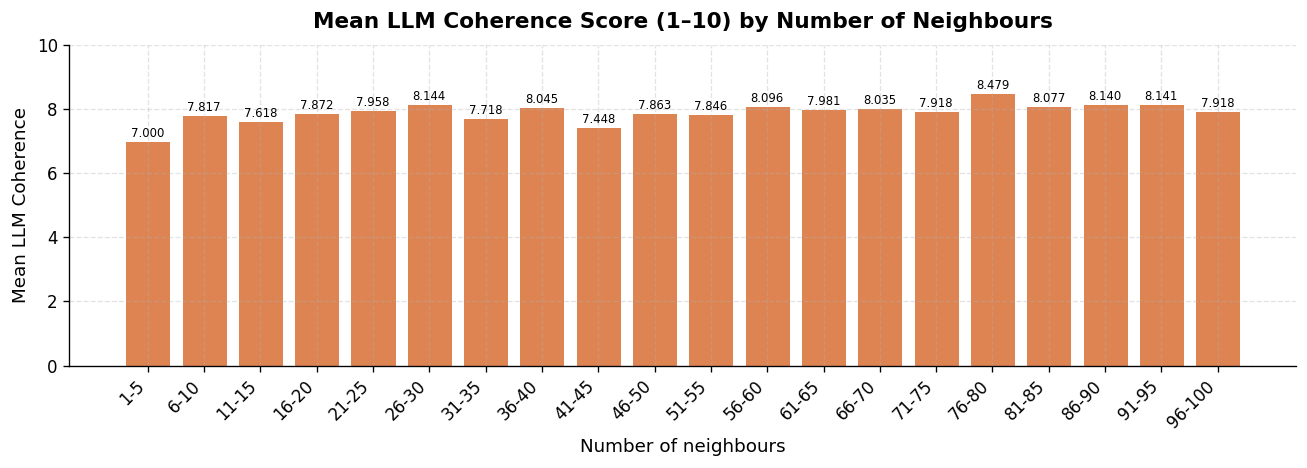

In [22]:
# ── 5. Mean LLM Coherence ─────────────────────────────────────────────────────
coh_mean = weighted_group_mean(df, 'llm_coherence')
bar_plot(coh_mean,
         title='Mean LLM Coherence Score (1–10) by Number of Neighbours',
         ylabel='Mean LLM Coherence',
         color='#DD8452',
         ylim=(0, 10))

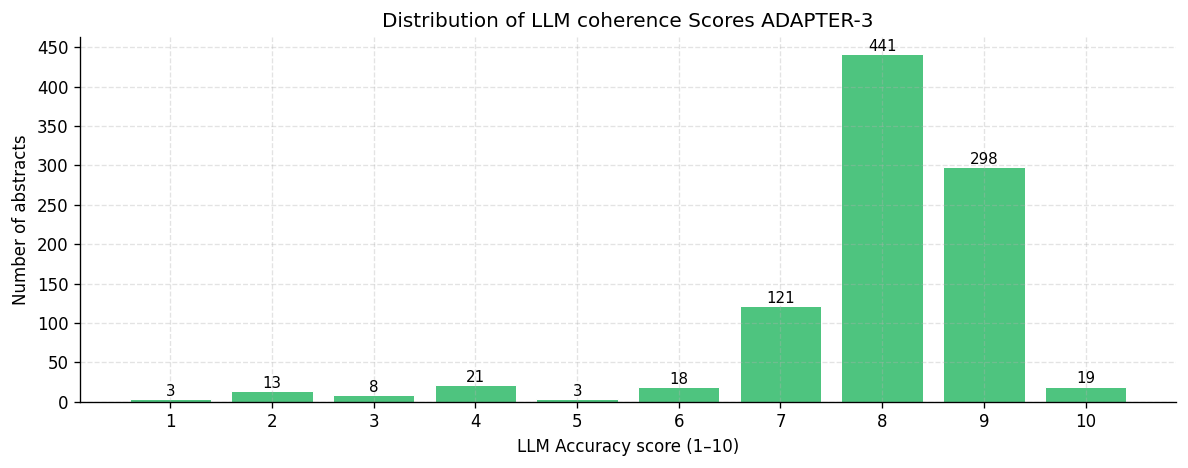

llm_coherence
1       3
2      13
3       8
4      21
5       3
6      18
7     121
8     441
9     298
10     19
Name: count, dtype: int64

In [23]:
# ── LLM Accuracy score distribution ───────────────────────────────────────────
SCORE_RANGE = list(range(1, 11))
acc_counts = (
    df['llm_coherence'].dropna().astype(int)
    .value_counts()
    .reindex(SCORE_RANGE, fill_value=0)
)

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(SCORE_RANGE, acc_counts.values, color="#4EC47F",
              edgecolor='white', linewidth=0.6)
for bar, v in zip(bars, acc_counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
            str(int(v)), ha='center', va='bottom', fontsize=9)

ax.set_title('Distribution of LLM coherence Scores ADAPTER-3')
ax.set_xlabel('LLM Accuracy score (1–10)')
ax.set_ylabel('Number of abstracts')
ax.set_xticks(SCORE_RANGE)
ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
plt.tight_layout()
plt.show()

acc_counts

In [24]:
# ── Mean llm_accuracy excluding low-coherence (1, 2) samples ─────────────────
filtered_df = df[~df['llm_coherence'].isin([1, 2])]

print(f'Excluded {len(df) - len(filtered_df)} rows with llm_coherence in [1, 2]')
print(f'Mean llm_accuracy (all rows):      {df["llm_accuracy"].mean():.4f}')
print(f'Mean llm_accuracy (excluding 1,2): {filtered_df["llm_accuracy"].mean():.4f}')


Excluded 16 rows with llm_coherence in [1, 2]
Mean llm_accuracy (all rows):      1.3143
Mean llm_accuracy (excluding 1,2): 1.3186


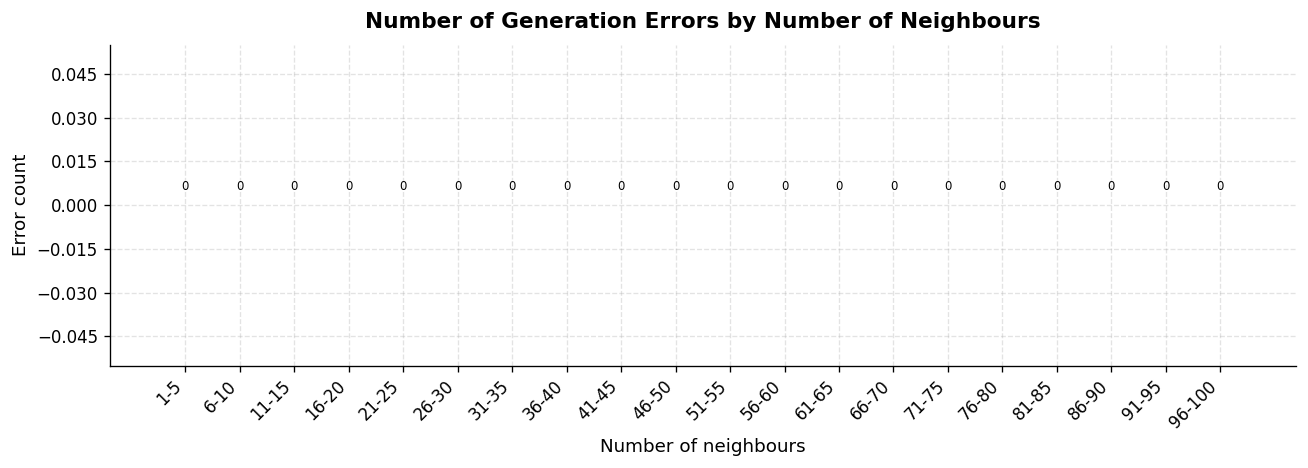

In [25]:
# ── 6. Number of Errors ───────────────────────────────────────────────────────
error_counts = df[df['is_error']].groupby('neighbor_group', observed=True).size().reindex(NEIGHBOR_GROUPS, fill_value=0)
bar_plot(error_counts,
         title='Number of Generation Errors by Number of Neighbours',
         ylabel='Error count',
         color='#CCB974',
         int_yaxis=True)

In [26]:
# ── 5 examples each of llm_coherence score 1 and 2 ───────────────────────────
low_coherence_sample = (
    df[df['llm_coherence'].isin([1, 2])]
    .sort_values('llm_coherence')
    .groupby('llm_coherence', sort=True)
    .apply(lambda g: g.head(5))
    .reset_index(drop=True)
    [['node_id', 'original_abstract', 'generated_abstract', 'llm_coherence']]
)

pd.set_option('display.max_colwidth', 2000)
low_coherence_sample


/var/folders/zc/tkfty0q10mx3n2n85rgs661h0000gn/T/ipykernel_16217/3088027966.py:6: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.head(5))


,node_id,original_abstract,generated_abstract,llm_coherence
0,93848,"Decentralized solutions to finite-sum minimization are of significant importance in many signal processing, control, and machine learning applications. In such settings, the data is distributed over a network of arbitrarily-connected nodes and raw data sharing is prohibitive often due to communication or privacy constraints. In this article, we review decentralized stochastic first-order optimization methods and illustrate some recent improvements based on gradient tracking and variance reduction, focusing particularly on smooth and strongly-convex objective functions. We provide intuitive illustrations of the main technical ideas as well as applications of the algorithms in the context of decentralized training of machine learning models.",We consider the problem of distributed estimation of a parameter vector in a network of agents. Each agent has access to a set of noisy measurements of the parameter vector and communicates with its neighbors to improve the estimation accuracy. We propose a distributed algorithm that is based on the Alternating Direction Method of Multipliers (ADMM) and is guaranteed to converge to the optimal estimate. We also propose a distributed algorithm that is based on the Alternating Direction Method of Multipliers (ADMM) and is guaranteed to converge to the optimal estimate. We also propose a distributed algorithm that is based on the Alternating Direction Method of Multipliers (ADMM) and is guaranteed to converge to the optimal estimate. We also propose a distributed algorithm that is based on the Alternating Direction Method of Multipliers (ADMM) and is guaranteed to converge to the optimal estimate. We also propose a distributed algorithm that is based on the Alternating Direction Method of Multipliers (ADMM) and is guaranteed to converge to the optimal estimate. We also propose a distributed algorithm that is based on the Alternating Direction Method of Multipliers (ADMM) and is guaranteed to converge to the optimal estimate. We also propose a distributed algorithm that is based on the Alternating Direction Method of Multipliers (ADMM) and is guaranteed to converge to the optimal estimate. We also propose a distributed algorithm that is based on the Alternating Direction Method of Multipliers (ADMM) and is guaranteed to converge to the optimal estimate. We also propose a distributed algorithm that is based on the Alternating Direction Method of Multipliers (ADMM) and,1
1,127664,"Big data production in industrial Internet of Things (IIoT) is evident due to the massive deployment of sensors and Internet of Things (IoT) devices. However, big data processing is challenging due to limited computational, networking and storage resources at IoT device-end. Big data analytics (BDA) is expected to provide operational- and customer-level intelligence in IIoT systems. Although numerous studies on IIoT and BDA exist, only a few studies have explored the convergence of the two paradigms. In this study, we investigate the recent BDA technologies, algorithms and techniques that can lead to the development of intelligent IIoT systems. We devise a taxonomy by classifying and categorising the literature on the basis of important parameters (e.g. data sources, analytics tools, analytics techniques, requirements, industrial analytics applications and analytics types). We present the frameworks and case studies of the various enterprises that have benefited from BDA. We also enumerate the considerable opportunities introduced by BDA in IIoT.We identify and discuss the indispensable challenges that remain to be addressed as future research directions as well.","The problem of finding the most influential nodes in a network has been extensively studied in the literature. In this paper, we propose a novel approach to this problem based on the concept of network diffusion. We define the influence of a node as the expected number of nodes that can be i

In [27]:
# ── 2 examples per llm_accuracy score ────────────────────────────────────────
sample = (
    df[df['llm_accuracy'].notna()]
    .sort_values('llm_accuracy')
    .groupby('llm_accuracy', sort=True)
    .apply(lambda g: g.head(2))
    .reset_index(drop=True)
    [['node_id', 'original_abstract', 'generated_abstract', 'llm_accuracy']]
)

pd.set_option('display.max_colwidth', 2000)
sample

/var/folders/zc/tkfty0q10mx3n2n85rgs661h0000gn/T/ipykernel_16217/263653425.py:6: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.head(2))


,node_id,original_abstract,generated_abstract,llm_accuracy
0,65735,"The complementary characteristics of active and passive depth sensing techniques motivate the fusion of the Li-DAR sensor and stereo camera for improved depth perception. Instead of directly fusing estimated depths across LiDAR and stereo modalities, we take advantages of the stereo matching network with two enhanced techniques: Input Fusion and Conditional Cost Volume Normalization (CCVNorm) on the LiDAR information. The proposed framework is generic and closely integrated with the cost volume component that is commonly utilized in stereo matching neural networks. We experimentally verify the efficacy and robustness of our method on the KITTI Stereo and Depth Completion datasets, obtaining favorable performance against various fusion strategies. Moreover, we demonstrate that, with a hierarchical extension of CCVNorm, the proposed method brings only slight overhead to the stereo matching network in terms of computation time and model size. For project page, see this https URL","We propose a novel approach to the problem of learning a deep neural network for image classification. Our approach is based on the observation that the training of a deep network can be viewed as a sequence of tasks, where each task is to learn a new layer of the network. We propose to use a reinforcement learning agent to learn a policy for choosing the next task to perform. The agent is trained to maximize the accuracy of the network on a validation set. We show that our approach can be used to train deep networks with a much smaller number of parameters than the original network, while achieving similar or better performance.",1
1,85472,"Non-orthogonal multiple access (NOMA) allows multiple users to share a time-frequency resource block by using different power levels. An important challenge associated with NOMA is the selection of users that share a resource block. This is referred to as clustering, which generally exploits the channel disparity (i.e. distinctness) among the users. We discuss clustering and the related resource allocation challenges (e.g. power allocation) associated with NOMA and highlight open problems that require further investigation. We review the related literature on exploiting channel disparity for clustering and resource allocation. There have been several misconceptions regarding NOMA clustering including: 1) clustering users with low channel disparity is detrimental, 2) similar power allocation is disastrous for NOMA. We clarify such misunderstandings with numerical examples.","In this paper, we consider the problem of secure transmission in a multi-antenna Gaussian wiretap channel with a friendly jammer. We assume that the friendly jammer is equipped with multiple antennas and the eavesdropper is equipped with a single antenna. We propose a new secure transmission scheme, which is based on the idea of artificial noise (AN) aided transmission. In this scheme, the transmitter sends the desired signal and the AN to the legitimate receiver and the eavesdropper, respectively. The AN is designed to be aligned with the desired signal at the legitimate receiver, but not aligned with the desired signal at the eavesdropper. We show that the proposed scheme can achieve a higher secrecy rate than the existing schemes. We also show that the proposed scheme can achieve the secrecy capacity of the Gaussian wiretap channel with a friendly jammer.",1
2,136175,"Deep neural networks and in particular, deep neural classifiers have become an integral part of many modern applications. Despite their practical success, we still have limited knowledge of how they work and the demand for such an understanding is evergrowing. In this regard, one crucial aspect of deep neural network classifiers that can help us deepen our knowledge about their decision-making behavior is to investigate their decision boundaries. Nevertheless, this is contingent upon having access to samples popu

In [28]:
# ── Negative category counts ──────────────────────────────────────────────────
NEG_COLS = [
    'cat_wrong_domain', 'cat_multi_paper_contamination', 'cat_wrong_methodology',
    'cat_wrong_task', 'cat_too_generic', 'cat_truncated_incomplete',
]
NEG_LABELS = [
    'Wrong domain', 'Multi-paper contamination', 'Wrong methodology',
    'Wrong task', 'Too generic', 'Truncated / incomplete',
]

neg_counts = df[NEG_COLS].sum().values

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(NEG_LABELS, neg_counts, color='#C44E52', edgecolor='white', linewidth=0.6)
for bar, v in zip(bars, neg_counts):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
            str(int(v)), ha='center', va='bottom', fontsize=9)
ax.set_ylabel('Count', fontsize=11)
ax.set_title('Negative category frequency', fontsize=13, fontweight='bold', pad=10)
ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
plt.xticks(rotation=15, ha='right')
fig.tight_layout()
plt.show()

KeyError: "None of [Index(['cat_wrong_domain', 'cat_multi_paper_contamination',\n       'cat_wrong_methodology', 'cat_wrong_task', 'cat_too_generic',\n       'cat_truncated_incomplete'],\n      dtype='object')] are in the [columns]"

Category definitions:
- wrong_domain: The generated abstract is about a completely different research field or application domain from the original.
- multi_paper_contamination: The text reads like a stitched-together mixture of multiple unrelated papers rather than one coherent abstract.
- wrong_methodology: The domain is broadly correct but describes different techniques or algorithms than the original.
- wrong_task: Same broad field but the specific problem being solved is different (e.g., classification instead of regression, MT instead of summarisation).
- too_generic: Correct domain but described at such a high level of generality that it lacks the specific terminology and framing of the original.
- truncated_incomplete: The abstract ends abruptly mid-sentence or is clearly unfinished.


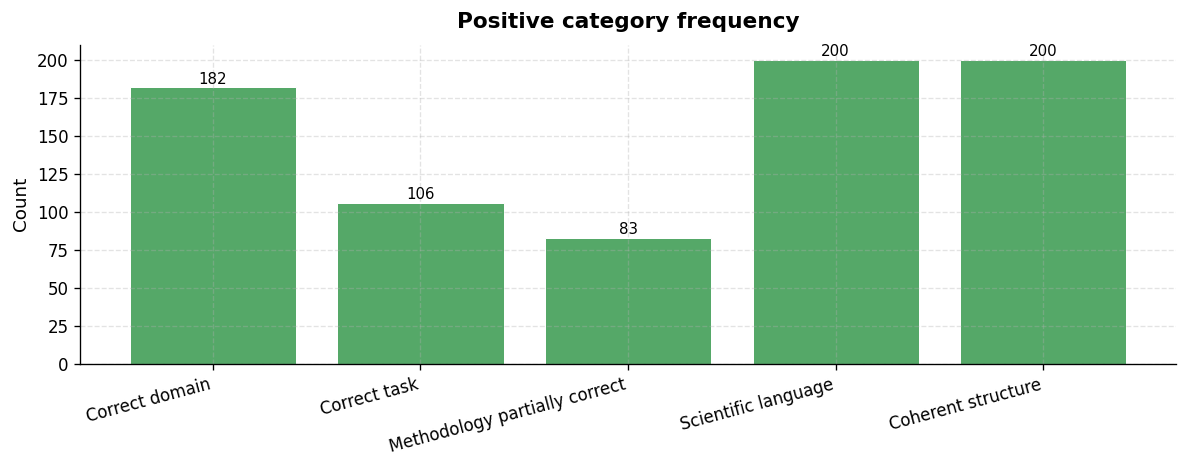

In [ ]:
# ── Positive category counts ──────────────────────────────────────────────────
POS_COLS = [
    'cat_correct_domain', 'cat_correct_task', 'cat_methodology_partially_correct',
    'cat_scientific_language', 'cat_coherent_structure',
]
POS_LABELS = [
    'Correct domain', 'Correct task', 'Methodology partially correct',
    'Scientific language', 'Coherent structure',
]

pos_counts = df[POS_COLS].sum().values

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(POS_LABELS, pos_counts, color='#55A868', edgecolor='white', linewidth=0.6)
for bar, v in zip(bars, pos_counts):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
            str(int(v)), ha='center', va='bottom', fontsize=9)
ax.set_ylabel('Count', fontsize=11)
ax.set_title('Positive category frequency', fontsize=13, fontweight='bold', pad=10)
ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
plt.xticks(rotation=15, ha='right')
fig.tight_layout()
plt.show()